In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## roc-curve

**ROC curves of AI-text detectors on Reddit texts that start with gpt-3.5-turbo output and are finished by a human.** Ours (DNA-GPT) detects on a sliding window, with (W/ P) or without (W/o P) the golden prompt, while the baselines classify the whole text; AUCs are computed from the curves with the trapezoidal rule, and the dashed diagonal marks chance. DNA-GPT reaches an AUC of 0.987 with and 0.905 without the golden prompt, against 0.647 for GPTZero and 0.565 for OpenAI.

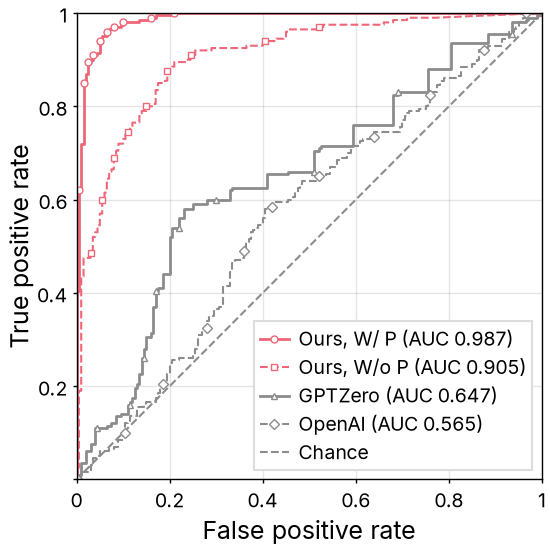

In [2]:
data = json.load(open("../data/roc-curve.json"))
methods = {m["name"]: m for m in data["methods"]}

fig, ax = plt.subplots(figsize=(2.75, 2.75))
series = [
    ("Ours: W/ P", "Ours, W/ P", colors["ours"], "-", "o"),
    ("Ours: W/o P", "Ours, W/o P", colors["ours"], "--", "s"),
    ("GPTZero", "GPTZero", colors["neutral"], "-", "^"),
    ("OpenAI", "OpenAI", colors["neutral"], "--", "D"),
]
for key, name, color, linestyle, marker in series:
    fpr, tpr = methods[key]["fpr"], methods[key]["tpr"]
    auc = np.trapezoid(tpr, fpr)
    linewidth = None if linestyle == "-" else paper.dashed_width
    ax.plot(fpr, tpr, linestyle=linestyle, linewidth=linewidth, marker=marker, markevery=max(1, len(fpr) // 10),
            color=color, label=f"{name} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=paper.dashed_width, color=colors["neutral"], zorder=1, label="Chance")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:g}")
ax.set_yticks(ax.get_yticks(), labels=["", *[f"{v:g}" for v in ax.get_yticks()[1:]]])
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right")
fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/roc-curve.pdf")
fig.savefig("../outputs/roc-curve.png")
plt.show()